In [15]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/telco_features.csv")

X = df.drop(columns=["Churn"])
y = df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print()
print("Churn rate in y:", round(y.mean() * 100, 2), "%")

X shape: (7043, 21)
y shape: (7043,)

Churn rate in y: 26.54 %


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges",
            "num_services", "has_security_or_support", "auto_payment"]

cat_cols = ["Partner", "Dependents", "MultipleLines", "InternetService",
            "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
            "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling",
            "PaymentMethod", "tenure_group"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_prep.shape)
print("Test data after preprocessing:    ", X_test_prep.shape)
print()
print("Average of the 7 scaled number columns (should be about 0):")
print(X_train_prep[:, :7].mean(axis=0).round(2))

Training data after preprocessing: (5634, 48)
Test data after preprocessing:     (1409, 48)

Average of the 7 scaled number columns (should be about 0):
[ 0. -0. -0. -0. -0.  0. -0.]


In [17]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/telco_features.csv")
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)

Training set: (5634, 21)
Test set:     (1409, 21)


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_prep, y_train)

lr_pred = lr.predict(X_test_prep)
lr_proba = lr.predict_proba(X_test_prep)[:, 1]

print("Accuracy: ", round(accuracy_score(y_test, lr_pred), 3))
print("Precision:", round(precision_score(y_test, lr_pred), 3))
print("Recall:   ", round(recall_score(y_test, lr_pred), 3))
print("F1-score: ", round(f1_score(y_test, lr_pred), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, lr_proba), 3))

Accuracy:  0.798
Precision: 0.651
Recall:    0.519
F1-score:  0.577
ROC-AUC:   0.843


In [19]:
from sklearn.tree import DecisionTreeClassifier

tree_deep = DecisionTreeClassifier(random_state=42)
tree_deep.fit(X_train_prep, y_train)

tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(X_train_prep, y_train)

print("UNLIMITED TREE")
print("  Train accuracy:", round(tree_deep.score(X_train_prep, y_train), 3))
print("  Test accuracy: ", round(tree_deep.score(X_test_prep, y_test), 3))
print()
print("TREE WITH max_depth=5")
print("  Train accuracy:", round(tree.score(X_train_prep, y_train), 3))
print("  Test accuracy: ", round(tree.score(X_test_prep, y_test), 3))

tree_pred = tree.predict(X_test_prep)
tree_proba = tree.predict_proba(X_test_prep)[:, 1]

print()
print("FULL METRICS (max_depth=5 tree)")
print("Accuracy: ", round(accuracy_score(y_test, tree_pred), 3))
print("Precision:", round(precision_score(y_test, tree_pred), 3))
print("Recall:   ", round(recall_score(y_test, tree_pred), 3))
print("F1-score: ", round(f1_score(y_test, tree_pred), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, tree_proba), 3))

UNLIMITED TREE
  Train accuracy: 0.998
  Test accuracy:  0.727

TREE WITH max_depth=5
  Train accuracy: 0.804
  Test accuracy:  0.798

FULL METRICS (max_depth=5 tree)
Accuracy:  0.798
Precision: 0.635
Recall:    0.567
F1-score:  0.599
ROC-AUC:   0.83


In [20]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42
)
rf.fit(X_train_prep, y_train)

print("Train accuracy:", round(rf.score(X_train_prep, y_train), 3))
print("Test accuracy: ", round(rf.score(X_test_prep, y_test), 3))

rf_pred = rf.predict(X_test_prep)
rf_proba = rf.predict_proba(X_test_prep)[:, 1]

print()
print("FULL METRICS (Random Forest)")
print("Accuracy: ", round(accuracy_score(y_test, rf_pred), 3))
print("Precision:", round(precision_score(y_test, rf_pred), 3))
print("Recall:   ", round(recall_score(y_test, rf_pred), 3))
print("F1-score: ", round(f1_score(y_test, rf_pred), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, rf_proba), 3))

Train accuracy: 0.826
Test accuracy:  0.803

FULL METRICS (Random Forest)
Accuracy:  0.803
Precision: 0.675
Recall:    0.5
F1-score:  0.575
ROC-AUC:   0.843


In [21]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)
xgb.fit(X_train_prep, y_train)

print("Train accuracy:", round(xgb.score(X_train_prep, y_train), 3))
print("Test accuracy: ", round(xgb.score(X_test_prep, y_test), 3))

xgb_pred = xgb.predict(X_test_prep)
xgb_proba = xgb.predict_proba(X_test_prep)[:, 1]

print()
print("FULL METRICS (XGBoost)")
print("Accuracy: ", round(accuracy_score(y_test, xgb_pred), 3))
print("Precision:", round(precision_score(y_test, xgb_pred), 3))
print("Recall:   ", round(recall_score(y_test, xgb_pred), 3))
print("F1-score: ", round(f1_score(y_test, xgb_pred), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, xgb_proba), 3))

Train accuracy: 0.827
Test accuracy:  0.805

FULL METRICS (XGBoost)
Accuracy:  0.805
Precision: 0.671
Recall:    0.519
F1-score:  0.585
ROC-AUC:   0.846


In [22]:
models = {
    "Logistic Regression": (lr_pred, lr_proba),
    "Decision Tree": (tree_pred, tree_proba),
    "Random Forest": (rf_pred, rf_proba),
    "XGBoost": (xgb_pred, xgb_proba),
}

rows = []
for name, (pred, proba) in models.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.798,0.651,0.519,0.577,0.843
Decision Tree,0.798,0.635,0.567,0.599,0.830
Random Forest,0.803,0.675,0.500,0.575,0.843
XGBoost,0.805,0.671,0.519,0.585,0.846


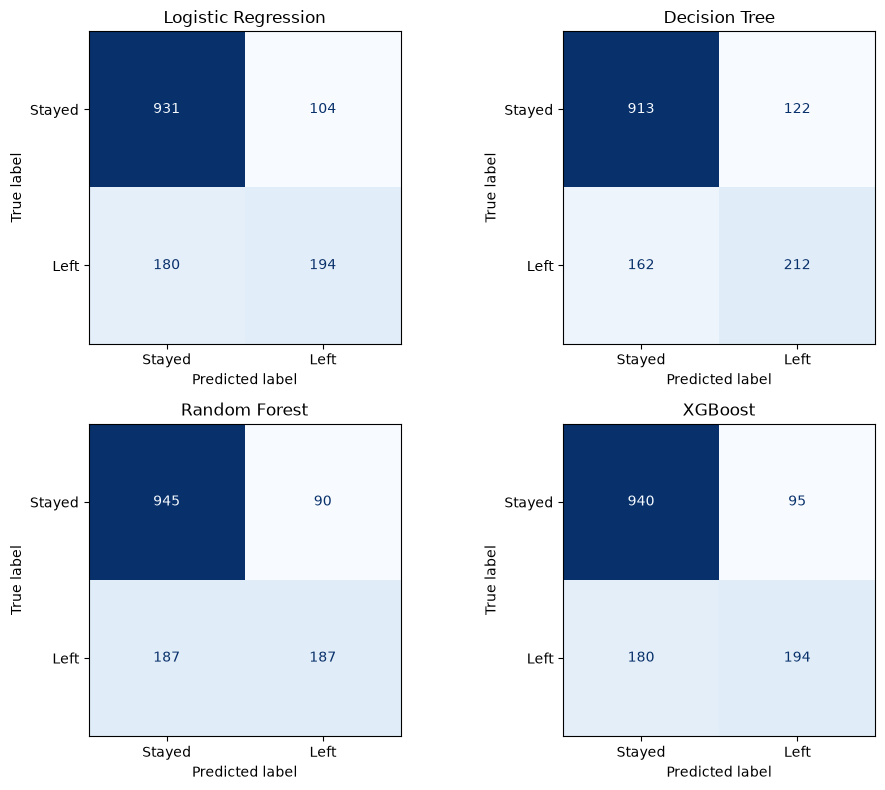

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (name, (pred, proba)) in zip(axes.flatten(), models.items()):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Left"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)

plt.tight_layout()
plt.show()

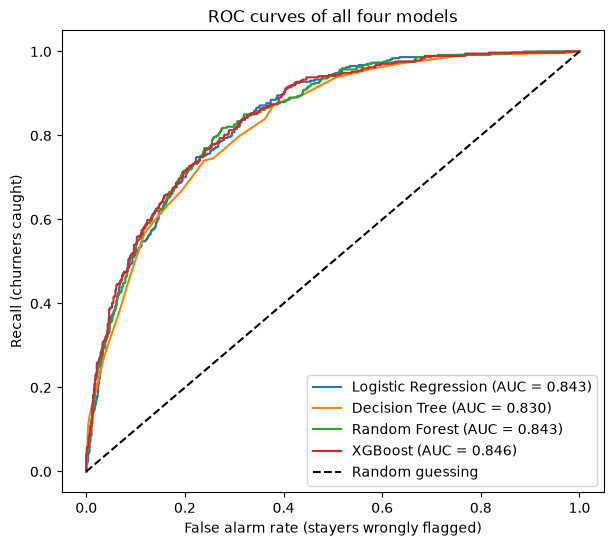

In [24]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))

for name, (pred, proba) in models.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False alarm rate (stayers wrongly flagged)")
plt.ylabel("Recall (churners caught)")
plt.title("ROC curves of all four models")
plt.legend(loc="lower right")
plt.show()

In [25]:
rows = []
for t in [0.5, 0.4, 0.35, 0.3, 0.25]:
    p = (xgb_proba >= t).astype(int)
    rows.append({
        "Cutoff": t,
        "Customers flagged": int(p.sum()),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
    })

pd.DataFrame(rows).set_index("Cutoff").round(3)

,Customers flagged,Precision,Recall,F1
Cutoff,,,,
0.50,289,0.671,0.519,0.585
0.40,421,0.587,0.660,0.621
0.35,481,0.561,0.722,0.632
0.30,537,0.533,0.765,0.628
0.25,592,0.507,0.802,0.621


In [26]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

pipe = Pipeline([
    ("prep", preprocessor),
    ("model", XGBClassifier(eval_metric="logloss", random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 200, 300, 400],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 1.0],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    pipe, param_grid,
    n_iter=20, scoring="roc_auc", cv=cv,
    random_state=42, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)

print()
print("Best cross-validation ROC-AUC:", round(search.best_score_, 4))
print("Best settings:")
for k, v in search.best_params_.items():
    print("  ", k.replace("model__", ""), "=", v)

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best cross-validation ROC-AUC: 0.8494
Best settings:
   subsample = 1.0
   n_estimators = 300
   min_child_weight = 1
   max_depth = 3
   learning_rate = 0.03
   colsample_bytree = 0.8


In [27]:
best_model = search.best_estimator_

tuned_pred = best_model.predict(X_test)
tuned_proba = best_model.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({
    "Before tuning": {
        "Train accuracy": xgb.score(X_train_prep, y_train),
        "Test accuracy": accuracy_score(y_test, xgb_pred),
        "Precision": precision_score(y_test, xgb_pred),
        "Recall": recall_score(y_test, xgb_pred),
        "F1": f1_score(y_test, xgb_pred),
        "ROC-AUC": roc_auc_score(y_test, xgb_proba),
    },
    "After tuning": {
        "Train accuracy": best_model.score(X_train, y_train),
        "Test accuracy": accuracy_score(y_test, tuned_pred),
        "Precision": precision_score(y_test, tuned_pred),
        "Recall": recall_score(y_test, tuned_pred),
        "F1": f1_score(y_test, tuned_pred),
        "ROC-AUC": roc_auc_score(y_test, tuned_proba),
    },
}).round(3)

comparison

,Before tuning,After tuning
Train accuracy,0.827,0.820
Test accuracy,0.805,0.808
Precision,0.671,0.675
Recall,0.519,0.532
F1,0.585,0.595
ROC-AUC,0.846,0.845


In [28]:
import shap

prep = best_model.named_steps["prep"]
xgb_tuned = best_model.named_steps["model"]

X_test_t = prep.transform(X_test)
names = [n.replace("num__", "").replace("cat__", "")
         for n in prep.get_feature_names_out()]
X_test_df = pd.DataFrame(X_test_t, columns=names)

explainer = shap.TreeExplainer(xgb_tuned)
shap_values = explainer(X_test_df)

print("SHAP values shape:", shap_values.values.shape)
print("Starting point (average model output):",
      round(float(np.mean(shap_values.base_values)), 2))

SHAP values shape: (1409, 48)
Starting point (average model output): -1.03


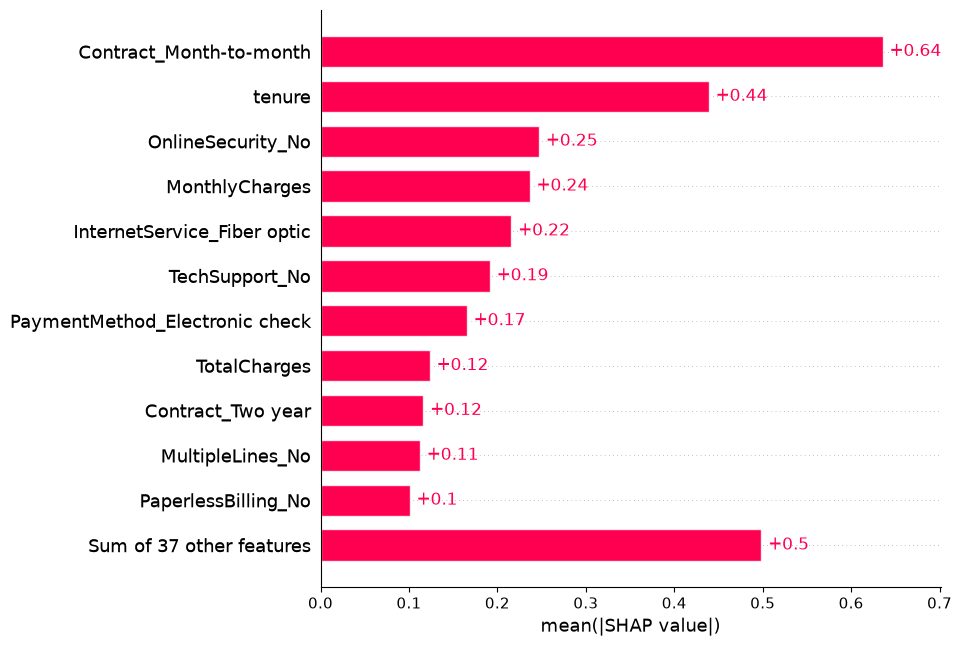

In [29]:
import matplotlib.pyplot as plt

shap.plots.bar(shap_values, max_display=12)

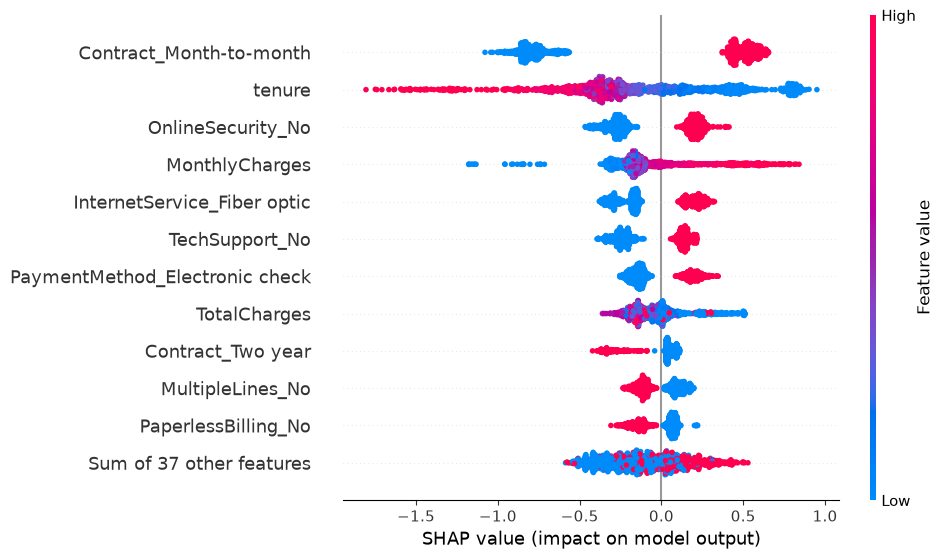

In [30]:
shap.plots.beeswarm(shap_values, max_display=12)

Contract                     Month-to-month
tenure                                    8
MonthlyCharges                       100.15
InternetService                 Fiber optic
OnlineSecurity                           No
TechSupport                             Yes
PaymentMethod       Credit card (automatic)
PaperlessBilling                        Yes
Name: 2280, dtype: object

Predicted churn probability: 0.8
Did this customer actually leave? No


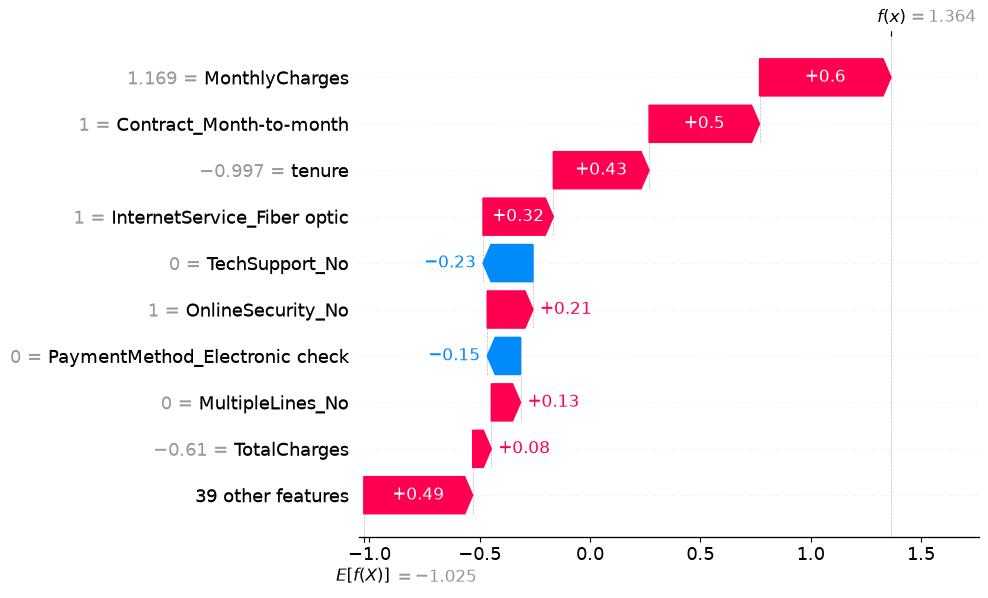

In [31]:
churn_prob = best_model.predict_proba(X_test)[:, 1]

high_risk = np.where(churn_prob >= 0.75)[0]
idx = high_risk[0]

show_cols = ["Contract", "tenure", "MonthlyCharges", "InternetService",
             "OnlineSecurity", "TechSupport", "PaymentMethod", "PaperlessBilling"]

print(X_test.iloc[idx][show_cols])
print()
print("Predicted churn probability:", round(churn_prob[idx], 2))
print("Did this customer actually leave?", "Yes" if y_test.iloc[idx] == 1 else "No")

shap.plots.waterfall(shap_values[idx], max_display=10)

In [ ]:
import joblib

joblib.dump(best_model, "../models/churn_model.joblib")
print("Model saved to ../models/churn_model.joblib")

Model saved to ../models/churn_model.joblib


: 